# Trabajo Práctico Integrador – Introducción al Análisis de Datos
## Entrega 6: Evaluación del modelo de clasificación

**Apellido y nombre:** Aguillón, Fernando  
**Comisión:** 5  
**Dataset:** E – reservas hoteleras  
**Recorrido:** SQL + R  
**Modelo:** Árbol de decisión (`rpart`)

**Propósito:** evaluar el árbol de decisión construido en la Entrega 5 para anticipar cancelaciones de reservas. Se reproducen la selección de variables, la preparación y el entrenamiento; luego se evalúa el modelo sobre observaciones que no utilizó para aprender.

**Archivo esperado en Google Colab:** `/content/hotel booking TPI grupo E.csv`

## 1. Objetivo y predictores

La variable objetivo es `is_canceled`: `0` = no cancelada y `1` = cancelada. Es clasificación supervisada porque el modelo aprende a partir de reservas cuyo resultado conocemos y predice una categoría para otras reservas.

Se mantienen los ocho predictores de la Entrega 5:

| Variable | Justificación |
|---|---|
| `hotel` | En el análisis anterior se observaron diferencias en las tasas de cancelación entre City Hotel y Resort Hotel. |
| `lead_time` | Las reservas canceladas presentaron una mediana de anticipación mayor. |
| `adr` | Se observaron diferencias entre grupos; debe confirmarse que esté disponible al registrar la reserva. |
| `market_segment` | Describe el segmento de mercado. |
| `distribution_channel` | Identifica el canal por el que llegó la reserva. |
| `deposit_type` | Describe el tipo de depósito o garantía. |
| `customer_type` | Caracteriza el tipo de cliente. |
| `previous_cancellations` | Resume cancelaciones anteriores del cliente. |

Se excluyen `booking_id` por ser identificador, `company` por su elevada proporción de faltantes y variables como `reservation_status` y `reservation_status_date`, que pueden revelar el resultado final. También se excluyen variables potencialmente posteriores al registro, como `assigned_room_type` y `booking_changes`.

**Consideración sobre ADR:** Se conserva esta variable como predictora bajo el supuesto de que su valor estaba disponible al momento de registrar la reserva. Esta decisión permite mantener la continuidad con la Entrega 5. En una aplicación real, sería necesario verificar que el valor utilizado corresponda efectivamente al momento de creación de la reserva y no a una actualización posterior.

## 2. Librerías y entorno SQL

DuckDB permite seleccionar los datos mediante SQL. R se utiliza para preparar los datos, entrenar el árbol y evaluar sus predicciones. En Linux se instala DuckDB desde Posit Package Manager sin forzar `type = "binary"`.

In [6]:
options(repos = c(CRAN = "https://cloud.r-project.org"))
options(timeout = 600)

if (!requireNamespace("DBI", quietly = TRUE)) install.packages("DBI")

if (!requireNamespace("duckdb", quietly = TRUE)) {
  arquitectura <- R.version$arch
  version_r <- paste(R.version$major, R.version$minor, sep = ".")
  repositorio_duckdb <- sprintf(
    "https://p3m.dev/cran/latest/bin/linux/manylinux_2_28-%s/%s",
    arquitectura, version_r
  )
  install.packages("duckdb", repos = repositorio_duckdb)
}

if (!requireNamespace("rpart", quietly = TRUE)) install.packages("rpart")

library(DBI)
library(duckdb)
library(rpart)

cat("Paquetes cargados correctamente.\n")
cat("DuckDB:", as.character(packageVersion("duckdb")), "\n")
cat("rpart:", as.character(packageVersion("rpart")), "\n")

Paquetes cargados correctamente.
DuckDB: 2.0.0 
rpart: 4.1.27 


## 3. Carga del dataset original

El notebook parte del CSV original y no de objetos creados en la Entrega 5. Si el archivo no está disponible en Colab, subilo desde el panel de archivos y verificá que conserve el nombre esperado.

In [7]:
ruta_csv <- "/content/hotel booking TPI grupo E.csv"

if (!file.exists(ruta_csv)) {
  stop("No se encontró el CSV. Subí 'hotel booking TPI grupo E.csv' a /content/ y volvé a ejecutar.")
}

datos_originales <- read.csv(
  ruta_csv, stringsAsFactors = FALSE,
  na.strings = c("", "NA"), check.names = FALSE
)

cat("Filas originales:", nrow(datos_originales), "\n")
cat("Columnas originales:", ncol(datos_originales), "\n")
stopifnot("is_canceled" %in% names(datos_originales))

Filas originales: 25000 
Columnas originales: 32 


## 4. Preparación inicial

Se mantienen los criterios anteriores: eliminar duplicados exactos, excluir `booking_id` y `company`, reemplazar faltantes de `children` por cero, identificar faltantes de `agent` y `country` mediante categorías explícitas y eliminar solo valores negativos de `adr`. Se conservan ceros y extremos de ADR. No se eliminan automáticamente reservas sin huéspedes.

La imputación de los predictores se realiza después de separar entrenamiento y prueba.

In [8]:
df <- datos_originales
filas_iniciales <- nrow(df)
duplicados_exactos <- sum(duplicated(df))
faltantes_children <- if ("children" %in% names(df)) sum(is.na(df$children)) else NA_integer_
adr_negativos <- if ("adr" %in% names(df)) sum(!is.na(df$adr) & df$adr < 0) else NA_integer_

df <- df[!duplicated(df), , drop = FALSE]
df <- df[, !(names(df) %in% intersect(c("booking_id", "company"), names(df))), drop = FALSE]

if ("children" %in% names(df)) df$children[is.na(df$children)] <- 0
if ("agent" %in% names(df)) {
  df$agent <- as.character(df$agent)
  df$agent[is.na(df$agent) | trimws(df$agent) == ""] <- "Sin agente"
}
if ("country" %in% names(df)) {
  df$country <- as.character(df$country)
  df$country[is.na(df$country) | trimws(df$country) == ""] <- "Sin especificar"
}
if ("adr" %in% names(df)) {
  df$adr <- as.numeric(df$adr)
  df <- df[is.na(df$adr) | df$adr >= 0, , drop = FALSE]
}

cat("Duplicados exactos eliminados:", duplicados_exactos, "\n")
cat("Faltantes originales de children:", faltantes_children, "\n")
cat("ADR negativos detectados:", adr_negativos, "\n")
cat("Filas originales:", filas_iniciales, "\n")
cat("Filas después de preparar:", nrow(df), "\n")

Duplicados exactos eliminados: 0 
Faltantes originales de children: 2 
ADR negativos detectados: 1 
Filas originales: 25000 
Filas después de preparar: 24999 


## 5. Selección de variables mediante SQL

Se seleccionan la variable objetivo y los mismos ocho predictores de la Entrega 5.

In [9]:
variables_requeridas <- c(
  "is_canceled", "hotel", "lead_time", "adr", "market_segment",
  "distribution_channel", "deposit_type", "customer_type",
  "previous_cancellations"
)
variables_faltantes <- setdiff(variables_requeridas, names(df))
if (length(variables_faltantes) > 0) {
  stop(paste("No se encontraron:", paste(variables_faltantes, collapse = ", ")))
}

df$is_canceled <- as.integer(as.character(df$is_canceled))
df$lead_time <- as.numeric(df$lead_time)
df$adr <- as.numeric(df$adr)
df$previous_cancellations <- as.numeric(df$previous_cancellations)

conexion <- DBI::dbConnect(duckdb::duckdb(), dbdir = ":memory:")
DBI::dbWriteTable(conexion, "reservas", df, overwrite = TRUE)

consulta_modelo <- "
SELECT is_canceled, hotel, lead_time, adr, market_segment,
       distribution_channel, deposit_type, customer_type,
       previous_cancellations
FROM reservas
WHERE is_canceled IN (0, 1)
"
datos_modelo <- DBI::dbGetQuery(conexion, consulta_modelo)

cat("Registros seleccionados por SQL:", nrow(datos_modelo), "\n")
cat("Columnas seleccionadas:", ncol(datos_modelo), "\n")
head(datos_modelo, 10)

duckdb keeps downloaded extensions and secrets in a temporary directory:
ℹ /tmp/RtmptKnU1R/duckdb
This is removed when the R session ends.
• Extensions are re-downloaded each session.
• Secrets are lost.
ℹ Run duckdb(shared_home = TRUE) (or create ~/.duckdb) to keep them (suitable for most users).
ℹ Run duckdb(shared_home = FALSE) to accept the temporary directory (and silence this message).
ℹ See ?duckdb_storage for details and alternatives.


Registros seleccionados por SQL: 24999 
Columnas seleccionadas: 9 


,is_canceled,hotel,lead_time,adr,market_segment,distribution_channel,deposit_type,customer_type,previous_cancellations
,<int>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>
1,0,City Hotel,2,150.00,Direct,Direct,No Deposit,Transient,0
2,0,Resort Hotel,1,48.00,Online TA,TA/TO,No Deposit,Transient,0
3,1,City Hotel,28,190.00,Online TA,TA/TO,No Deposit,Transient,0
4,0,Resort Hotel,31,76.38,Online TA,TA/TO,No Deposit,Transient,0
5,0,Resort Hotel,204,153.57,Direct,Direct,No Deposit,Transient,0
6,1,Resort Hotel,172,125.90,Direct,Direct,No Deposit,Transient,0
7,1,City Hotel,272,62.80,Groups,TA/TO,No Deposit,Transient-Party,1
8,0,City Hotel,138,101.49,Online TA,TA/TO,No Deposit,Transient,0
9,0,City Hotel,56,195.00,Direct,Direct,No Deposit,Transient,0


## 6. Diagnóstico de faltantes y clases

Se revisan los faltantes y la distribución de la variable objetivo. Si las clases están desbalanceadas, la exactitud por sí sola puede resultar engañosa.

In [10]:
resumen_faltantes <- data.frame(
  variable = names(datos_modelo),
  tipo = sapply(datos_modelo, function(x) class(x)[1]),
  faltantes = sapply(datos_modelo, function(x) sum(is.na(x))),
  porcentaje_faltantes = round(
    100 * sapply(datos_modelo, function(x) mean(is.na(x))), 2
  )
)
resumen_faltantes

,variable,tipo,faltantes,porcentaje_faltantes
,<chr>,<chr>,<int>,<dbl>
is_canceled,is_canceled,integer,0,0
hotel,hotel,character,0,0
lead_time,lead_time,numeric,0,0
adr,adr,numeric,0,0
market_segment,market_segment,character,0,0
distribution_channel,distribution_channel,character,0,0
deposit_type,deposit_type,character,0,0
customer_type,customer_type,character,0,0
previous_cancellations,previous_cancellations,numeric,0,0


In [11]:
table(datos_modelo$is_canceled, useNA = "ifany")
frecuencia_clases <- as.data.frame(prop.table(table(datos_modelo$is_canceled)) * 100)
names(frecuencia_clases) <- c("is_canceled", "porcentaje")
frecuencia_clases


    0     1 
15738  9261 

is_canceled,porcentaje
<fct>,<dbl>
0,62.95452
1,37.04548


## 7. Separación entre entrenamiento y prueba

Se utiliza aproximadamente el **80 %** para entrenamiento y el **20 %** para prueba, manteniendo la proporción de clases mediante selección estratificada. La semilla `2026` permite reproducir la separación.

El conjunto de prueba contiene observaciones que el modelo no utilizó para aprender. Evaluarlo allí permite aproximarse a su capacidad de **generalización**. Si el rendimiento en prueba empeorara mucho respecto del entrenamiento, podría ser una señal de **sobreajuste**.

In [12]:
datos_modelo <- datos_modelo[!is.na(datos_modelo$is_canceled), , drop = FALSE]
datos_modelo$is_canceled <- as.integer(datos_modelo$is_canceled)
if (!all(datos_modelo$is_canceled %in% c(0L, 1L))) {
  stop("is_canceled contiene valores distintos de 0 y 1.")
}

set.seed(2026)
indices_por_clase <- split(seq_len(nrow(datos_modelo)), datos_modelo$is_canceled)
indices_entrenamiento <- unlist(lapply(indices_por_clase, function(indices) {
  sample(indices, size = floor(0.80 * length(indices)))
}), use.names = FALSE)
indices_prueba <- setdiff(seq_len(nrow(datos_modelo)), indices_entrenamiento)

entrenamiento <- datos_modelo[indices_entrenamiento, , drop = FALSE]
prueba <- datos_modelo[indices_prueba, , drop = FALSE]

cat("Registros de entrenamiento:", nrow(entrenamiento), "\n")
cat("Registros de prueba:", nrow(prueba), "\n")
cat("\nProporción de clases en entrenamiento:\n")
print(prop.table(table(entrenamiento$is_canceled)))
cat("\nProporción de clases en prueba:\n")
print(prop.table(table(prueba$is_canceled)))

Registros de entrenamiento: 19998 
Registros de prueba: 5001 

Proporción de clases en entrenamiento:

       0        1 
0.629563 0.370437 

Proporción de clases en prueba:

        0         1 
0.6294741 0.3705259 


## 8. Tratamiento de faltantes sin fuga de información

Se conserva el procedimiento de la Entrega 5:
- Variables numéricas (`lead_time`, `adr`, `previous_cancellations`): faltantes reemplazados por la mediana calculada exclusivamente en entrenamiento. Esa misma mediana se aplica a prueba.
- Variables categóricas (`hotel`, `market_segment`, `distribution_channel`, `deposit_type`, `customer_type`): faltantes identificados como `Sin especificar`. Las categorías que aparezcan solo en prueba se codifican como `Otra categoría`.

Así, el conjunto de prueba no se utiliza para aprender los valores de preparación.

In [13]:
variables_numericas <- c("lead_time", "adr", "previous_cancellations")
variables_categoricas <- c(
  "hotel", "market_segment", "distribution_channel",
  "deposit_type", "customer_type"
)

medianas_entrenamiento <- list()
for (variable in variables_numericas) {
  entrenamiento[[variable]] <- as.numeric(entrenamiento[[variable]])
  prueba[[variable]] <- as.numeric(prueba[[variable]])
  mediana_calculada <- median(entrenamiento[[variable]], na.rm = TRUE)
  if (!is.finite(mediana_calculada)) {
    stop(paste("No se pudo calcular una mediana válida para", variable))
  }
  medianas_entrenamiento[[variable]] <- mediana_calculada
  entrenamiento[[variable]][is.na(entrenamiento[[variable]])] <- mediana_calculada
  prueba[[variable]][is.na(prueba[[variable]])] <- mediana_calculada
}

normalizar_categoria <- function(x) {
  x <- trimws(as.character(x))
  x[is.na(x) | x == ""] <- "Sin especificar"
  x
}

for (variable in variables_categoricas) {
  entrenamiento[[variable]] <- normalizar_categoria(entrenamiento[[variable]])
  prueba[[variable]] <- normalizar_categoria(prueba[[variable]])
  niveles <- unique(c(sort(unique(entrenamiento[[variable]])), "Otra categoría"))
  valores_prueba <- prueba[[variable]]
  valores_prueba[!valores_prueba %in% niveles] <- "Otra categoría"
  entrenamiento[[variable]] <- factor(entrenamiento[[variable]], levels = niveles)
  prueba[[variable]] <- factor(valores_prueba, levels = niveles)
}

entrenamiento$is_canceled <- factor(
  ifelse(entrenamiento$is_canceled == 1, "Cancelada", "No cancelada"),
  levels = c("No cancelada", "Cancelada")
)
prueba$is_canceled <- factor(
  ifelse(prueba$is_canceled == 1, "Cancelada", "No cancelada"),
  levels = c("No cancelada", "Cancelada")
)

cat("Medianas calculadas solo con entrenamiento:\n")
print(unlist(medianas_entrenamiento))
cat("\nFaltantes en entrenamiento:\n")
print(colSums(is.na(entrenamiento)))
cat("\nFaltantes en prueba:\n")
print(colSums(is.na(prueba)))

Medianas calculadas solo con entrenamiento:
             lead_time                    adr previous_cancellations 
                  69.0                   94.5                    0.0 

Faltantes en entrenamiento:
           is_canceled                  hotel              lead_time 
                     0                      0                      0 
                   adr         market_segment   distribution_channel 
                     0                      0                      0 
          deposit_type          customer_type previous_cancellations 
                     0                      0                      0 

Faltantes en prueba:
           is_canceled                  hotel              lead_time 
                     0                      0                      0 
                   adr         market_segment   distribution_channel 
                     0                      0                      0 
          deposit_type          customer_type previous_cancellati

## 9. Entrenamiento del árbol de decisión

Se reproduce el mismo modelo y configuración inicial de la Entrega 5: `rpart`, método `class`, `cp = 0.01`, profundidad máxima 5 y `minsplit = 20`. No se incorporan otros algoritmos ni se optimizan hiperparámetros: el propósito es evaluar el modelo trabajado.

In [14]:
set.seed(2026)
modelo_arbol <- rpart(
  is_canceled ~ .,
  data = entrenamiento,
  method = "class",
  control = rpart.control(cp = 0.01, maxdepth = 5, minsplit = 20)
)
print(modelo_arbol)

n= 19998 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

 1) root 19998 7408 No cancelada (0.629562956 0.370437044)  
   2) deposit_type=No Deposit,Refundable 17484 4911 No cancelada (0.719114619 0.280885381)  
     4) lead_time< 11.5 4072  445 No cancelada (0.890717092 0.109282908) *
     5) lead_time>=11.5 13412 4466 No cancelada (0.667014614 0.332985386)  
      10) previous_cancellations< 0.5 13036 4118 No cancelada (0.684105554 0.315894446) *
      11) previous_cancellations>=0.5 376   28 Cancelada (0.074468085 0.925531915) *
   3) deposit_type=Non Refund 2514   17 Cancelada (0.006762132 0.993237868) *


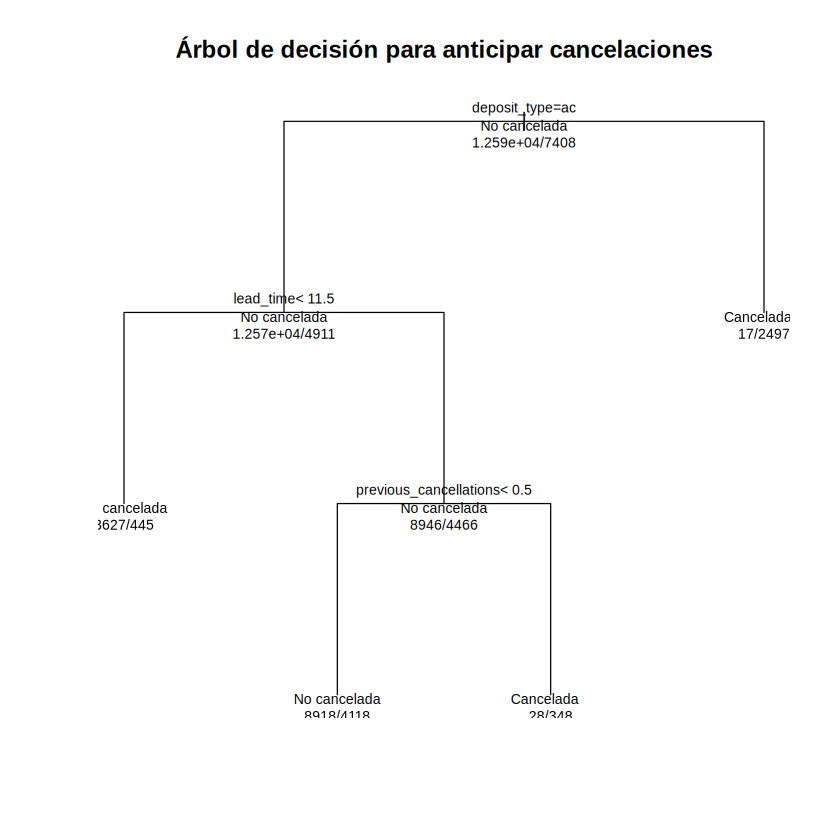

In [15]:
plot(modelo_arbol, uniform = TRUE,
     main = "Árbol de decisión para anticipar cancelaciones")
text(modelo_arbol, use.n = TRUE, all = TRUE, cex = 0.7)

## 10. Predicciones sobre el conjunto de prueba

Se predice la clase de cada reserva del conjunto de prueba y se compara el estado real con el predicho. La probabilidad estimada es una salida del modelo, no una certeza.

In [16]:
predicciones_clase <- predict(modelo_arbol, newdata = prueba, type = "class")
predicciones_probabilidad <- predict(modelo_arbol, newdata = prueba, type = "prob")

resultados_prueba <- data.frame(
  estado_real = prueba$is_canceled,
  estado_predicho = predicciones_clase,
  probabilidad_cancelacion = round(
    predicciones_probabilidad[, "Cancelada"], 4
  )
)
head(resultados_prueba, 20)

,estado_real,estado_predicho,probabilidad_cancelacion
,<fct>,<fct>,<dbl>
1,No cancelada,No cancelada,0.1093
7,Cancelada,Cancelada,0.9255
18,Cancelada,Cancelada,0.9932
25,Cancelada,No cancelada,0.3159
26,Cancelada,No cancelada,0.3159
28,No cancelada,No cancelada,0.3159
33,Cancelada,No cancelada,0.3159
34,Cancelada,No cancelada,0.3159
40,No cancelada,No cancelada,0.1093


## 11. Matriz de confusión

Consideramos **positiva** la clase `Cancelada`.

| Resultado | Significado |
|---|---|
| **Verdadero positivo (VP)** | La reserva se canceló y el modelo predijo cancelación. |
| **Verdadero negativo (VN)** | La reserva no se canceló y el modelo predijo que no se cancelaría. |
| **Falso positivo (FP)** | El modelo predijo cancelación, pero la reserva finalmente no se canceló. |
| **Falso negativo (FN)** | El modelo predijo que no se cancelaría, pero finalmente sí se canceló. |

En la matriz de R, las filas son el estado real y las columnas son el estado predicho.

In [17]:
matriz_confusion <- table(
  Real = prueba$is_canceled,
  Predicho = predicciones_clase
)
matriz_confusion

vn <- as.numeric(matriz_confusion["No cancelada", "No cancelada"])
fp <- as.numeric(matriz_confusion["No cancelada", "Cancelada"])
fn <- as.numeric(matriz_confusion["Cancelada", "No cancelada"])
vp <- as.numeric(matriz_confusion["Cancelada", "Cancelada"])

conteos <- data.frame(
  resultado = c("Verdaderos positivos (VP)", "Verdaderos negativos (VN)",
                "Falsos positivos (FP)", "Falsos negativos (FN)"),
  cantidad = c(vp, vn, fp, fn)
)
conteos

              Predicho
Real           No cancelada Cancelada
  No cancelada         3139         9
  Cancelada            1155       698

resultado,cantidad
<chr>,<dbl>
Verdaderos positivos (VP),698
Verdaderos negativos (VN),3139
Falsos positivos (FP),9
Falsos negativos (FN),1155


## 12. Métricas de clasificación

Las métricas se calculan considerando `Cancelada` como clase positiva:

- **Accuracy (exactitud):** proporción total de reservas clasificadas correctamente.
- **Precision (precisión):** de las reservas que el modelo predijo como canceladas, qué proporción realmente se canceló.
- **Recall (sensibilidad):** de todas las reservas que realmente se cancelaron, qué proporción detectó el modelo.
- **F1-score:** media armónica entre precision y recall; resume el equilibrio entre ambas.

\[
Accuracy = \frac{VP + VN}{VP + VN + FP + FN}
\]

\[
Precision = \frac{VP}{VP + FP}
\qquad
Recall = \frac{VP}{VP + FN}
\]

\[
F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}
\]

Si un denominador es cero, la métrica se informa como `NA`.

In [18]:
total <- vp + vn + fp + fn
accuracy <- if (total > 0) (vp + vn) / total else NA_real_
precision <- if ((vp + fp) > 0) vp / (vp + fp) else NA_real_
recall <- if ((vp + fn) > 0) vp / (vp + fn) else NA_real_
f1_score <- if (is.finite(precision) && is.finite(recall) &&
                (precision + recall) > 0) {
  2 * precision * recall / (precision + recall)
} else {
  NA_real_
}

metricas <- data.frame(
  metrica = c("Accuracy", "Precision", "Recall", "F1-score"),
  valor = round(c(accuracy, precision, recall, f1_score), 4),
  porcentaje = round(100 * c(accuracy, precision, recall, f1_score), 2)
)
metricas

metrica,valor,porcentaje
<chr>,<dbl>,<dbl>
Accuracy,0.7672,76.72
Precision,0.9873,98.73
Recall,0.3767,37.67
F1-score,0.5453,54.53


### Interpretación de las métricas obtenidas

- Un **accuracy** alto indica que el modelo acierta en una proporción elevada del total, pero puede ocultar dificultades para detectar cancelaciones si las clases están desbalanceadas.
- Una **precision** alta significa que, cuando el modelo alerta sobre una cancelación, suele acertar. Una precision baja implica más falsas alarmas.
- Un **recall** alto significa que el modelo detecta una proporción elevada de las cancelaciones reales. Un recall bajo implica que deja escapar muchas cancelaciones.
- Un **F1-score** alto indica un mejor equilibrio entre precision y recall.

In [19]:
cat(sprintf("Accuracy: %.4f. Clasificó correctamente el %.2f%% del conjunto de prueba.\n",
            accuracy, 100 * accuracy))
if (is.finite(precision)) {
  cat(sprintf("Precision: %.4f. De las reservas marcadas como canceladas, el %.2f%% realmente se canceló.\n",
              precision, 100 * precision))
} else {
  cat("Precision: no se calcula porque el modelo no predijo casos positivos.\n")
}
if (is.finite(recall)) {
  cat(sprintf("Recall: %.4f. Detectó el %.2f%% de las cancelaciones reales.\n",
              recall, 100 * recall))
} else {
  cat("Recall: no se calcula porque no hay cancelaciones reales en prueba.\n")
}
if (is.finite(f1_score)) {
  cat(sprintf("F1-score: %.4f. Resume el equilibrio entre precision y recall.\n", f1_score))
} else {
  cat("F1-score: no se pudo calcular con los valores disponibles.\n")
}

Accuracy: 0.7672. Clasificó correctamente el 76.72% del conjunto de prueba.
Precision: 0.9873. De las reservas marcadas como canceladas, el 98.73% realmente se canceló.
Recall: 0.3767. Detectó el 37.67% de las cancelaciones reales.
F1-score: 0.5453. Resume el equilibrio entre precision y recall.


## 13. Interpretación de los errores

**Falso positivo (FP):** el modelo alerta que una reserva se cancelará, pero el huésped finalmente sí se presenta. Puede provocar seguimiento innecesario, contactos que incomoden al cliente o decisiones equivocadas sobre la disponibilidad.

**Falso negativo (FN):** el modelo predice que una reserva se mantendrá, pero finalmente se cancela. El hotel podría perder la oportunidad de anticiparse, contactar al cliente, ajustar la ocupación o volver a ofrecer esa habitación con tiempo.

Un falso negativo puede ser especialmente relevante para la planificación porque una cancelación no anticipada puede dejar capacidad disponible sin tiempo suficiente para recuperarla. Sin embargo, la importancia relativa depende de los costos y la estrategia del establecimiento: demasiados falsos positivos también generan acciones innecesarias o perjudican la experiencia del huésped.

En los resultados obtenidos se observa una diferencia importante entre ambos tipos de errores: hubo 1.155 falsos negativos frente a solamente 9 falsos positivos. Esto indica que el modelo tiene dificultades para detectar reservas que finalmente se cancelan. Para un hotel, los falsos negativos pueden ser especialmente problemáticos porque reducen las posibilidades de anticipar la cancelación y volver a ofrecer la habitación disponible.

In [20]:
cat("Falsos positivos:", fp, "\n")
cat("Falsos negativos:", fn, "\n")
if (fp > fn) {
  cat("En el conjunto de prueba hubo más falsos positivos que falsos negativos.\n")
} else if (fn > fp) {
  cat("En el conjunto de prueba hubo más falsos negativos que falsos positivos.\n")
} else {
  cat("Hubo la misma cantidad de falsos positivos y falsos negativos.\n")
}

Falsos positivos: 9 
Falsos negativos: 1155 
En el conjunto de prueba hubo más falsos negativos que falsos positivos.


## 14. Conclusión

El árbol de decisión aporta información limitada para anticipar cancelaciones. Obtuvo un accuracy del 76,72 %, una precision del 98,73 %, un recall del 37,67 % y un F1-score del 54,53 %.

Aunque presenta una precisión elevada, solamente detectó el 37,67 % de las cancelaciones reales. En la matriz de confusión se observaron 9 falsos positivos y 1.155 falsos negativos. Esto significa que el modelo casi no genera falsas alarmas, pero deja pasar una cantidad importante de cancelaciones.

Considero que puede servir como una primera herramienta de orientación para identificar patrones de cancelación, pero todavía no es suficientemente eficaz para anticiparlas por sí solo. Entre sus limitaciones se encuentran la utilización de un único árbol de decisión con parámetros iniciales, la evaluación sobre una partición del dataset y la posibilidad de que los patrones no se mantengan en otros hoteles o períodos. Además, se trabajó bajo el supuesto de que los predictores, incluido ADR, estaban disponibles al registrar la reserva.

In [21]:
cat("RESUMEN DE EVALUACIÓN\n")
cat("---------------------\n")
cat("Reservas evaluadas:", total, "\n")
cat("Verdaderos positivos:", vp, "\n")
cat("Verdaderos negativos:", vn, "\n")
cat("Falsos positivos:", fp, "\n")
cat("Falsos negativos:", fn, "\n")
cat("Accuracy:", round(accuracy, 4), "\n")
cat("Precision:", round(precision, 4), "\n")
cat("Recall:", round(recall, 4), "\n")
cat("F1-score:", round(f1_score, 4), "\n")

RESUMEN DE EVALUACIÓN
---------------------
Reservas evaluadas: 5001 
Verdaderos positivos: 698 
Verdaderos negativos: 3139 
Falsos positivos: 9 
Falsos negativos: 1155 
Accuracy: 0.7672 
Precision: 0.9873 
Recall: 0.3767 
F1-score: 0.5453 
